In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
    export_text,
    _tree
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from IPython.display import display

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [25]:
DATA_PATH = "german_credit_data.csv"

df = pd.read_csv(DATA_PATH)

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (1000, 11)

Column names:
['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk']


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Unnamed: 0        1000 non-null   int64
 1   Age               1000 non-null   int64
 2   Sex               1000 non-null   str  
 3   Job               1000 non-null   int64
 4   Housing           1000 non-null   str  
 5   Saving accounts   817 non-null    str  
 6   Checking account  606 non-null    str  
 7   Credit amount     1000 non-null   int64
 8   Duration          1000 non-null   int64
 9   Purpose           1000 non-null   str  
 10  Risk              1000 non-null   str  
dtypes: int64(5), str(6)
memory usage: 115.1 KB

Missing values:


,Missing Values
Unnamed: 0,0
Age,0
Sex,0
Job,0
Housing,0
Saving accounts,183
Checking account,394
Credit amount,0
Duration,0
Purpose,0



Duplicate rows: 0


In [26]:
df = df.copy()

# Remove unnecessary exported index columns
id_columns = [
    col for col in df.columns
    if col.lower().startswith("unnamed:")
]

df = df.drop(columns=id_columns)

# Find the target column
target_candidates = [
    col for col in df.columns
    if col.lower().strip() == "risk"
]

if not target_candidates:
    raise ValueError(
        "Risk column not found. Check the dataset file and its columns."
    )

TARGET = target_candidates[0]

# Remove rows where the target label is missing
df = df.dropna(subset=[TARGET]).copy()

# Standardize target labels
df[TARGET] = df[TARGET].astype(str).str.strip().str.lower()

print("Target column:", TARGET)
print("Dataset shape after basic cleaning:", df.shape)

print("\nTarget values:")
display(df[TARGET].value_counts().to_frame("Customer Count"))

Target column: Risk
Dataset shape after basic cleaning: (1000, 10)

Target values:


,Customer Count
Risk,
good,700
bad,300


In [27]:
target_mapping = {
    "good": 0,
    "bad": 1
}

unexpected_labels = set(df[TARGET].unique()) - set(target_mapping)

if unexpected_labels:
    raise ValueError(
        f"Unexpected Risk labels: {unexpected_labels}. "
        "Update target_mapping to match your dataset."
    )

y = df[TARGET].map(target_mapping).astype(int)

X = df.drop(columns=[TARGET]).copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget mapping:")
print(target_mapping)

print("\nEncoded target distribution:")
display(
    y.map({
        0: "Good risk",
        1: "Bad risk"
    }).value_counts().to_frame("Customer Count")
)

Feature shape: (1000, 9)
Target shape: (1000,)

Target mapping:
{'good': 0, 'bad': 1}

Encoded target distribution:


,Customer Count
Risk,
Good risk,700
Bad risk,300


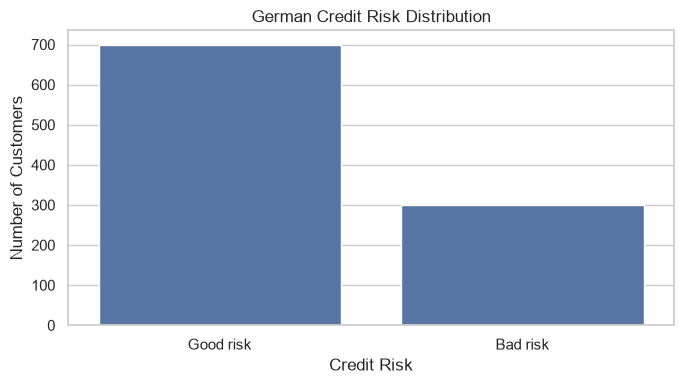

In [28]:
risk_counts = y.map({
    0: "Good risk",
    1: "Bad risk"
}).value_counts()

plt.figure(figsize=(7, 4))

sns.barplot(
    x=risk_counts.index,
    y=risk_counts.values
)

plt.title("German Credit Risk Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [29]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_train_val
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nTraining risk distribution:")
display(y_train.value_counts().rename(index={
    0: "Good risk",
    1: "Bad risk"
}).to_frame("Count"))

Training set: (600, 9)
Validation set: (200, 9)
Test set: (200, 9)

Training risk distribution:


,Count
Risk,
Good risk,420
Bad risk,180


In [30]:
# Identify numerical and categorical features
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing
numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

# Categorical preprocessing
# Replace missing categorical values with "Unknown"
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)

# Fit preprocessing ONLY on training data
X_train_encoded = preprocessor.fit_transform(X_train)

# Transform validation and test data without refitting
X_val_encoded = preprocessor.transform(X_val)
X_test_encoded = preprocessor.transform(X_test)

# Retrieve encoded feature names
feature_names = preprocessor.get_feature_names_out()

print("Preprocessing completed successfully.")

print("\nNumerical features:", numeric_features)
print("Categorical features:", categorical_features)

print("\nEncoded training shape:", X_train_encoded.shape)
print("Encoded validation shape:", X_val_encoded.shape)
print("Encoded test shape:", X_test_encoded.shape)

print(
    "\nMissing values in encoded training data:",
    np.isnan(X_train_encoded.toarray() if hasattr(
        X_train_encoded, "toarray"
    ) else X_train_encoded).sum()
)

Preprocessing completed successfully.

Numerical features: ['Age', 'Job', 'Credit amount', 'Duration']
Categorical features: ['Sex', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']

Encoded training shape: (600, 26)
Encoded validation shape: (200, 26)
Encoded test shape: (200, 26)

Missing values in encoded training data: 0


In [31]:
def calculate_entropy(labels):
    labels = np.asarray(labels)

    if len(labels) == 0:
        return 0.0

    counts = Counter(labels)
    total = len(labels)
    entropy = 0.0

    for count in counts.values():
        probability = count / total
        entropy -= probability * np.log2(probability)

    return entropy


sample_labels = [0, 0, 1, 1]

print("Sample labels:", sample_labels)
print("Entropy:", round(calculate_entropy(sample_labels), 4))

Sample labels: [0, 0, 1, 1]
Entropy: 1.0


In [32]:
def calculate_gini(labels):
    labels = np.asarray(labels)

    if len(labels) == 0:
        return 0.0

    counts = Counter(labels)
    total = len(labels)

    return 1 - sum(
        (count / total) ** 2
        for count in counts.values()
    )


sample_labels = [0, 0, 1, 1]

print("Sample labels:", sample_labels)
print("Gini impurity:", round(calculate_gini(sample_labels), 4))

Sample labels: [0, 0, 1, 1]
Gini impurity: 0.5


In [33]:
def calculate_information_gain(parent, left, right):
    total = len(parent)

    if total == 0:
        return 0.0

    weighted_child_entropy = (
        len(left) / total * calculate_entropy(left)
        + len(right) / total * calculate_entropy(right)
    )

    return calculate_entropy(parent) - weighted_child_entropy

In [34]:
def calculate_gini_gain(parent, left, right):
    total = len(parent)

    if total == 0:
        return 0.0

    weighted_child_gini = (
        len(left) / total * calculate_gini(left)
        + len(right) / total * calculate_gini(right)
    )

    return calculate_gini(parent) - weighted_child_gini

In [35]:
parent = np.array([0, 0, 0, 1, 1, 1])

left_A = np.array([0, 0, 1])
right_A = np.array([0, 1, 1])

left_B = np.array([0, 0, 0])
right_B = np.array([1, 1, 1])

splits = {
    "Split A": (left_A, right_A),
    "Split B": (left_B, right_B)
}

results = []

for split_name, (left, right) in splits.items():
    results.append({
        "Split": split_name,
        "Information Gain": calculate_information_gain(
            parent, left, right
        ),
        "Gini Gain": calculate_gini_gain(
            parent, left, right
        )
    })

display(pd.DataFrame(results).round(4))

,Split,Information Gain,Gini Gain
0,Split A,0.0817,0.0556
1,Split B,1.0000,0.5000


In [36]:
numeric_features_scratch = X_train.select_dtypes(
    include=np.number
).columns.tolist()

if not numeric_features_scratch:
    raise ValueError(
        "No numerical features are available for the manual tree."
    )

scratch_imputer = SimpleImputer(strategy="median")

X_train_scratch = pd.DataFrame(
    scratch_imputer.fit_transform(X_train[numeric_features_scratch]),
    columns=numeric_features_scratch,
    index=X_train.index
)

X_val_scratch = pd.DataFrame(
    scratch_imputer.transform(X_val[numeric_features_scratch]),
    columns=numeric_features_scratch,
    index=X_val.index
)

y_train_scratch = y_train.copy()
y_val_scratch = y_val.copy()

print("Numerical features:", numeric_features_scratch)
print("Training rows:", len(X_train_scratch))
print("Validation rows:", len(X_val_scratch))

Numerical features: ['Age', 'Job', 'Credit amount', 'Duration']
Training rows: 600
Validation rows: 200


In [37]:
def find_best_numeric_split(X_data, labels, criterion="entropy"):
    labels = np.asarray(labels)

    best_split = None
    best_score = -np.inf

    for feature in X_data.columns:
        values = X_data[feature].to_numpy(dtype=float)
        unique_values = np.unique(values)

        if len(unique_values) < 2:
            continue

        thresholds = (
            unique_values[:-1] + unique_values[1:]
        ) / 2

        for threshold in thresholds:
            left_mask = values <= threshold
            right_mask = values > threshold

            left_labels = labels[left_mask]
            right_labels = labels[right_mask]

            if len(left_labels) == 0 or len(right_labels) == 0:
                continue

            if criterion == "entropy":
                score = calculate_information_gain(
                    labels, left_labels, right_labels
                )
            elif criterion == "gini":
                score = calculate_gini_gain(
                    labels, left_labels, right_labels
                )
            else:
                raise ValueError(
                    "criterion must be 'entropy' or 'gini'."
                )

            if score > best_score:
                best_score = score
                best_split = {
                    "feature": feature,
                    "threshold": float(threshold),
                    "score": float(score)
                }

    return best_split


print("Best entropy split:")
print(
    find_best_numeric_split(
        X_train_scratch,
        y_train_scratch.to_numpy(),
        criterion="entropy"
    )
)

print("\nBest Gini split:")
print(
    find_best_numeric_split(
        X_train_scratch,
        y_train_scratch.to_numpy(),
        criterion="gini"
    )
)

Best entropy split:
{'feature': 'Duration', 'threshold': 16.5, 'score': 0.03271947765901018}

Best Gini split:
{'feature': 'Duration', 'threshold': 16.5, 'score': 0.018473282442748207}


In [38]:
def majority_class(labels):
    counts = Counter(labels)
    highest_count = max(counts.values())

    # If classes tie, choose the smaller label.
    # For this dataset: 0 = Good risk, 1 = Bad risk.
    return min(
        label
        for label, count in counts.items()
        if count == highest_count
    )


def build_simple_tree(
    X_data,
    labels,
    max_depth=3,
    criterion="entropy",
    depth=0
):
    labels = np.asarray(labels)

    # Handle an empty node safely
    if len(labels) == 0:
        return {"prediction": 0}

    # Stop if all customers belong to the same class
    if len(np.unique(labels)) == 1:
        return {"prediction": int(labels[0])}

    # Stop when maximum depth is reached
    if depth >= max_depth:
        return {
            "prediction": int(majority_class(labels))
        }

    # Find the best numerical split
    split = find_best_numeric_split(
        X_data.reset_index(drop=True),
        labels,
        criterion=criterion
    )

    # Stop if no useful split exists
    if split is None or split["score"] <= 0:
        return {
            "prediction": int(majority_class(labels))
        }

    feature = split["feature"]
    threshold = split["threshold"]

    values = X_data[feature].to_numpy(dtype=float)

    left_mask = values <= threshold
    right_mask = values > threshold

    # Ensure both branches contain customers
    if not left_mask.any() or not right_mask.any():
        return {
            "prediction": int(majority_class(labels))
        }

    # Recursively build left and right branches
    left_tree = build_simple_tree(
        X_data.loc[left_mask].reset_index(drop=True),
        labels[left_mask],
        max_depth=max_depth,
        criterion=criterion,
        depth=depth + 1
    )

    right_tree = build_simple_tree(
        X_data.loc[right_mask].reset_index(drop=True),
        labels[right_mask],
        max_depth=max_depth,
        criterion=criterion,
        depth=depth + 1
    )

    return {
        "feature": feature,
        "threshold": threshold,
        "prediction": int(majority_class(labels)),
        "left": left_tree,
        "right": right_tree
    }


# Build the from-scratch decision tree
scratch_tree = build_simple_tree(
    X_train_scratch.reset_index(drop=True),
    y_train_scratch.to_numpy(),
    max_depth=3,
    criterion="entropy"
)

print("From-scratch decision tree built successfully.")
print("\nTree structure:")
print(scratch_tree)

From-scratch decision tree built successfully.

Tree structure:
{'feature': 'Duration', 'threshold': 16.5, 'prediction': 0, 'left': {'feature': 'Duration', 'threshold': 8.5, 'prediction': 0, 'left': {'feature': 'Credit amount', 'threshold': 3181.0, 'prediction': 0, 'left': {'prediction': 0}, 'right': {'prediction': 0}}, 'right': {'feature': 'Credit amount', 'threshold': 954.5, 'prediction': 0, 'left': {'prediction': 0}, 'right': {'prediction': 0}}}, 'right': {'feature': 'Credit amount', 'threshold': 11307.0, 'prediction': 0, 'left': {'feature': 'Duration', 'threshold': 47.5, 'prediction': 0, 'left': {'prediction': 0}, 'right': {'prediction': 1}}, 'right': {'feature': 'Duration', 'threshold': 37.5, 'prediction': 1, 'left': {'prediction': 1}, 'right': {'prediction': 1}}}}


In [ ]:
def trace_prediction(tree, sample):
    path = []
    current_node = tree

    # Follow the decision path until reaching a leaf
    while "feature" in current_node:
        feature = current_node["feature"]
        threshold = current_node["threshold"]
        value = sample[feature]

        if value <= threshold:
            path.append(
                f"{feature}: {value:.3f} <= "
                f"{threshold:.3f} -> LEFT"
            )
            current_node = current_node["left"]

        else:
            path.append(
                f"{feature}: {value:.3f} > "
                f"{threshold:.3f} -> RIGHT"
            )
            current_node = current_node["right"]

    prediction = current_node["prediction"]

    path.append(f"Final prediction: {prediction}")

    return prediction, path

# Trace the first three validation customers
for i in range(min(3, len(X_val_scratch))):
    sample = X_val_scratch.iloc[i]

    prediction, path = trace_prediction(
        scratch_tree,
        sample
    )

    actual = int(y_val_scratch.iloc[i])

    print(f"\nValidation customer {i + 1}")

    print("Decision path:")
    for step in path:
        print(step)

    print(
        "Predicted risk:",
        "Bad risk" if prediction == 1 else "Good risk"
    )

    print(
        "Actual risk:",
        "Bad risk" if actual == 1 else "Good risk"
    )


# Evaluate the scratch tree on the complete validation set
validation_predictions = []

for i in range(len(X_val_scratch)):
    prediction, _ = trace_prediction(
        scratch_tree,
        X_val_scratch.iloc[i]
    )

    validation_predictions.append(prediction)


scratch_val_accuracy = accuracy_score(
    y_val_scratch,
    validation_predictions
)

print("\nFrom-scratch tree validation accuracy:",
      round(scratch_val_accuracy, 4))


Validation customer 1
Decision path:
Duration: 9.000 <= 16.500 -> LEFT
Duration: 9.000 > 8.500 -> RIGHT
Credit amount: 2030.000 > 954.500 -> RIGHT
Final prediction: 0
Predicted risk: Good risk
Actual risk: Good risk

Validation customer 2
Decision path:
Duration: 21.000 > 16.500 -> RIGHT
Credit amount: 5003.000 <= 11307.000 -> LEFT
Duration: 21.000 <= 47.500 -> LEFT
Final prediction: 0
Predicted risk: Good risk
Actual risk: Bad risk

Validation customer 3
Decision path:
Duration: 15.000 <= 16.500 -> LEFT
Duration: 15.000 > 8.500 -> RIGHT
Credit amount: 1360.000 > 954.500 -> RIGHT
Final prediction: 0
Predicted risk: Good risk
Actual risk: Good risk

From-scratch tree validation accuracy: 0.7


In [40]:
# Part B: Train Decision Trees with different maximum depths

depth_values = [2, 4, 6, 10, None]

depth_models = {}
depth_results = []

for depth in depth_values:

    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        random_state=RANDOM_STATE
    )

    # Train using training data only
    model.fit(X_train_encoded, y_train)

    # Make predictions
    train_predictions = model.predict(X_train_encoded)
    val_predictions = model.predict(X_val_encoded)

    # Calculate accuracy             
    train_accuracy = accuracy_score(
        y_train,
        train_predictions
    )

    val_accuracy = accuracy_score(
        y_val,
        val_predictions
    )

    # Save the trained model
    depth_models[depth] = model

    # Store results
    depth_results.append({
        "Max Depth": str(depth),
        "Training Accuracy": train_accuracy,
        "Validation Accuracy": val_accuracy,
        "Actual Tree Depth": model.get_depth(),
        "Number of Leaves": model.get_n_leaves()
    })

depth_results_df = pd.DataFrame(depth_results)

print("Decision Trees trained successfully.")

display(depth_results_df.round(4))

Decision Trees trained successfully.


,Max Depth,Training Accuracy,Validation Accuracy,Actual Tree Depth,Number of Leaves
0,2,0.7383,0.650,2,4
1,4,0.7933,0.680,4,15
2,6,0.8617,0.665,6,41
3,10,0.9667,0.665,10,108
4,None,1.0000,0.655,14,136


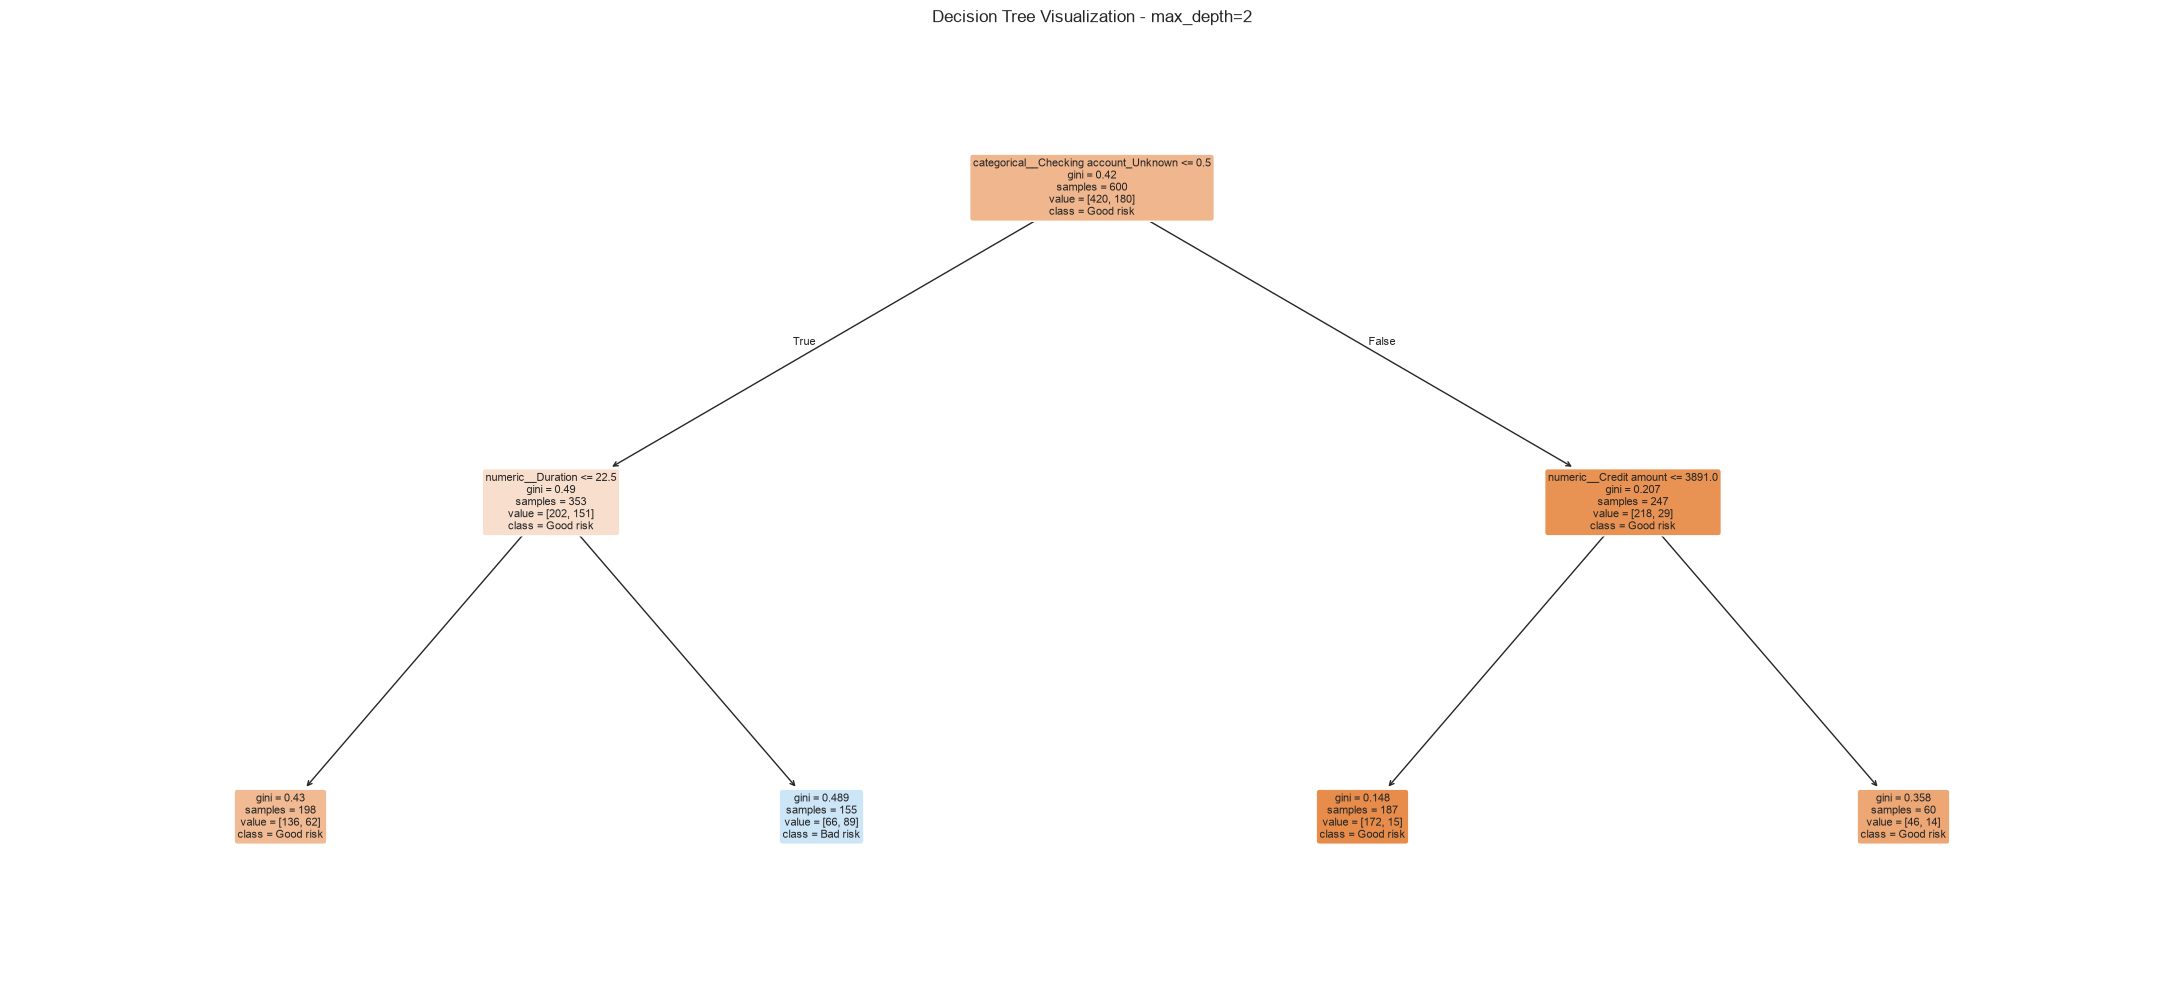

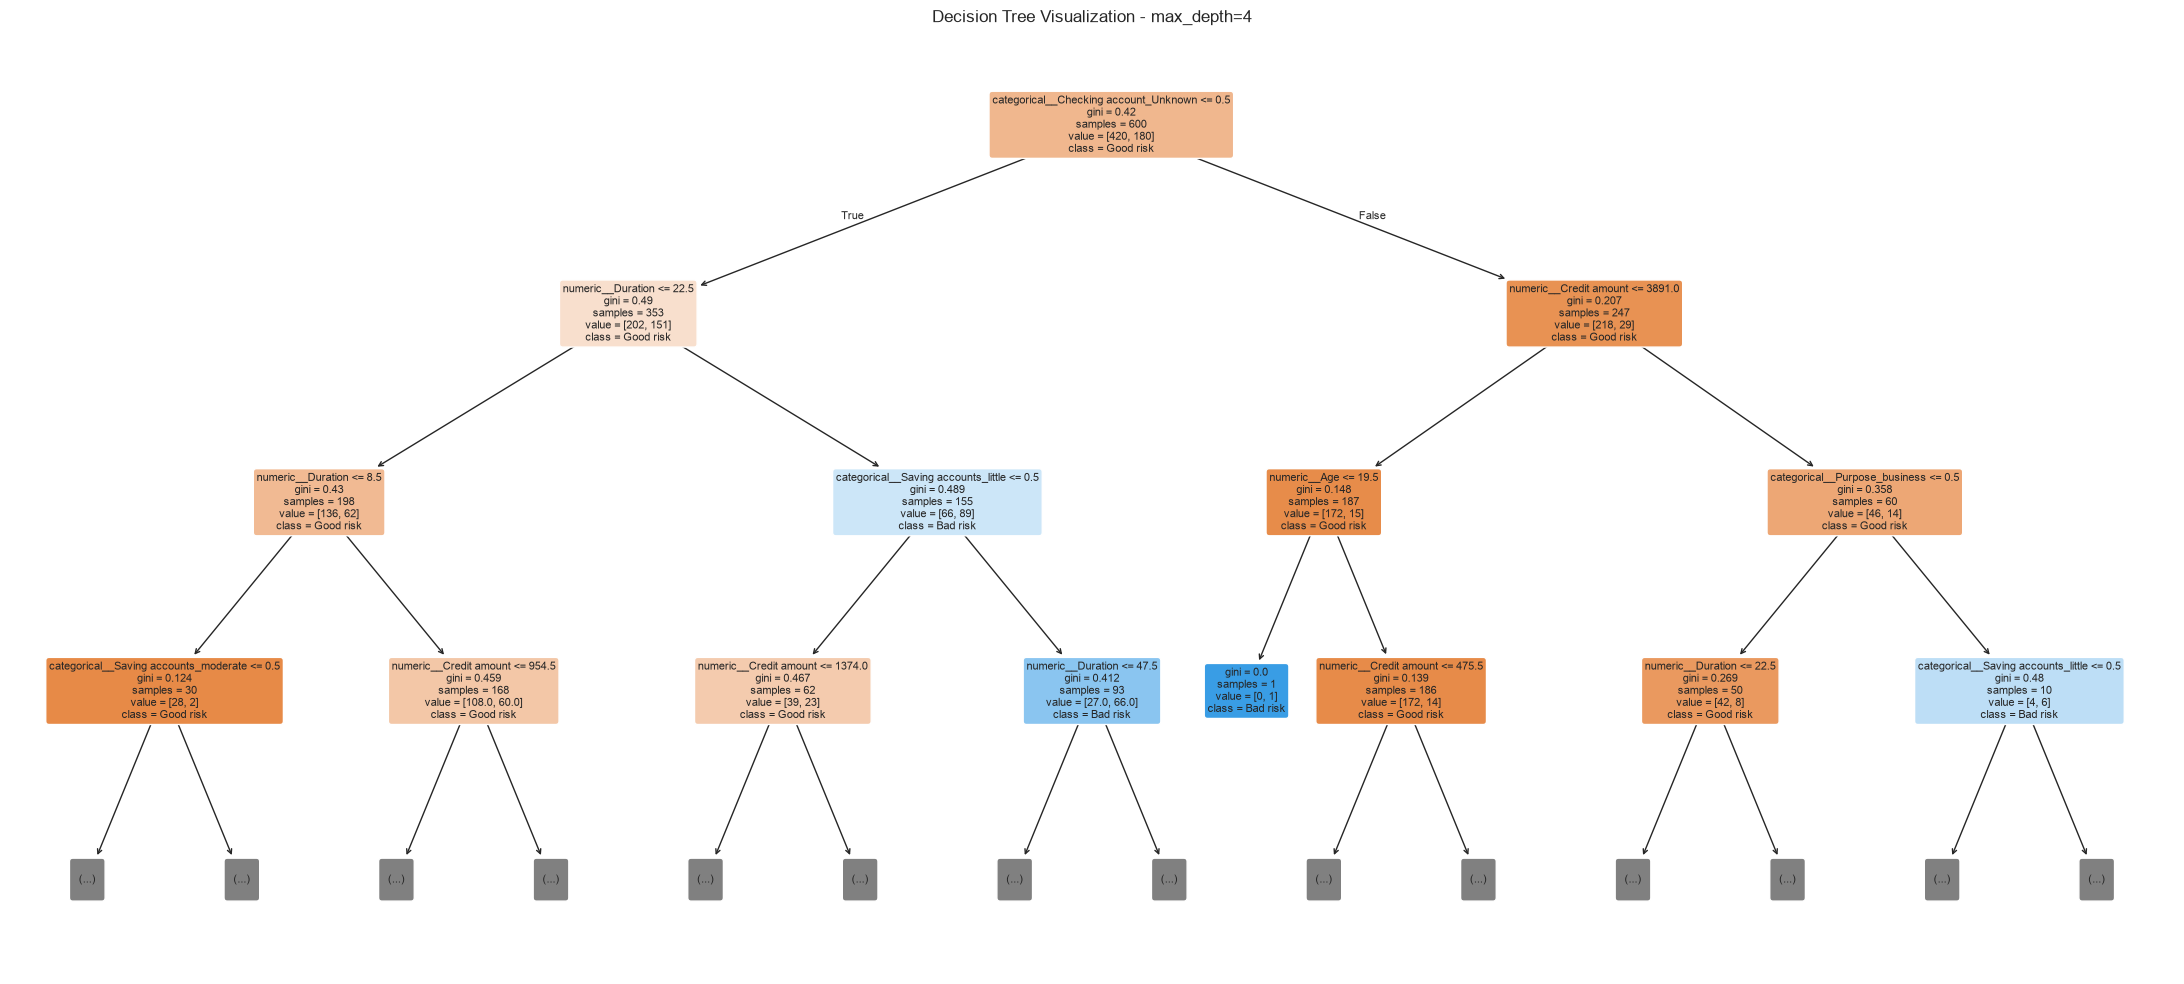

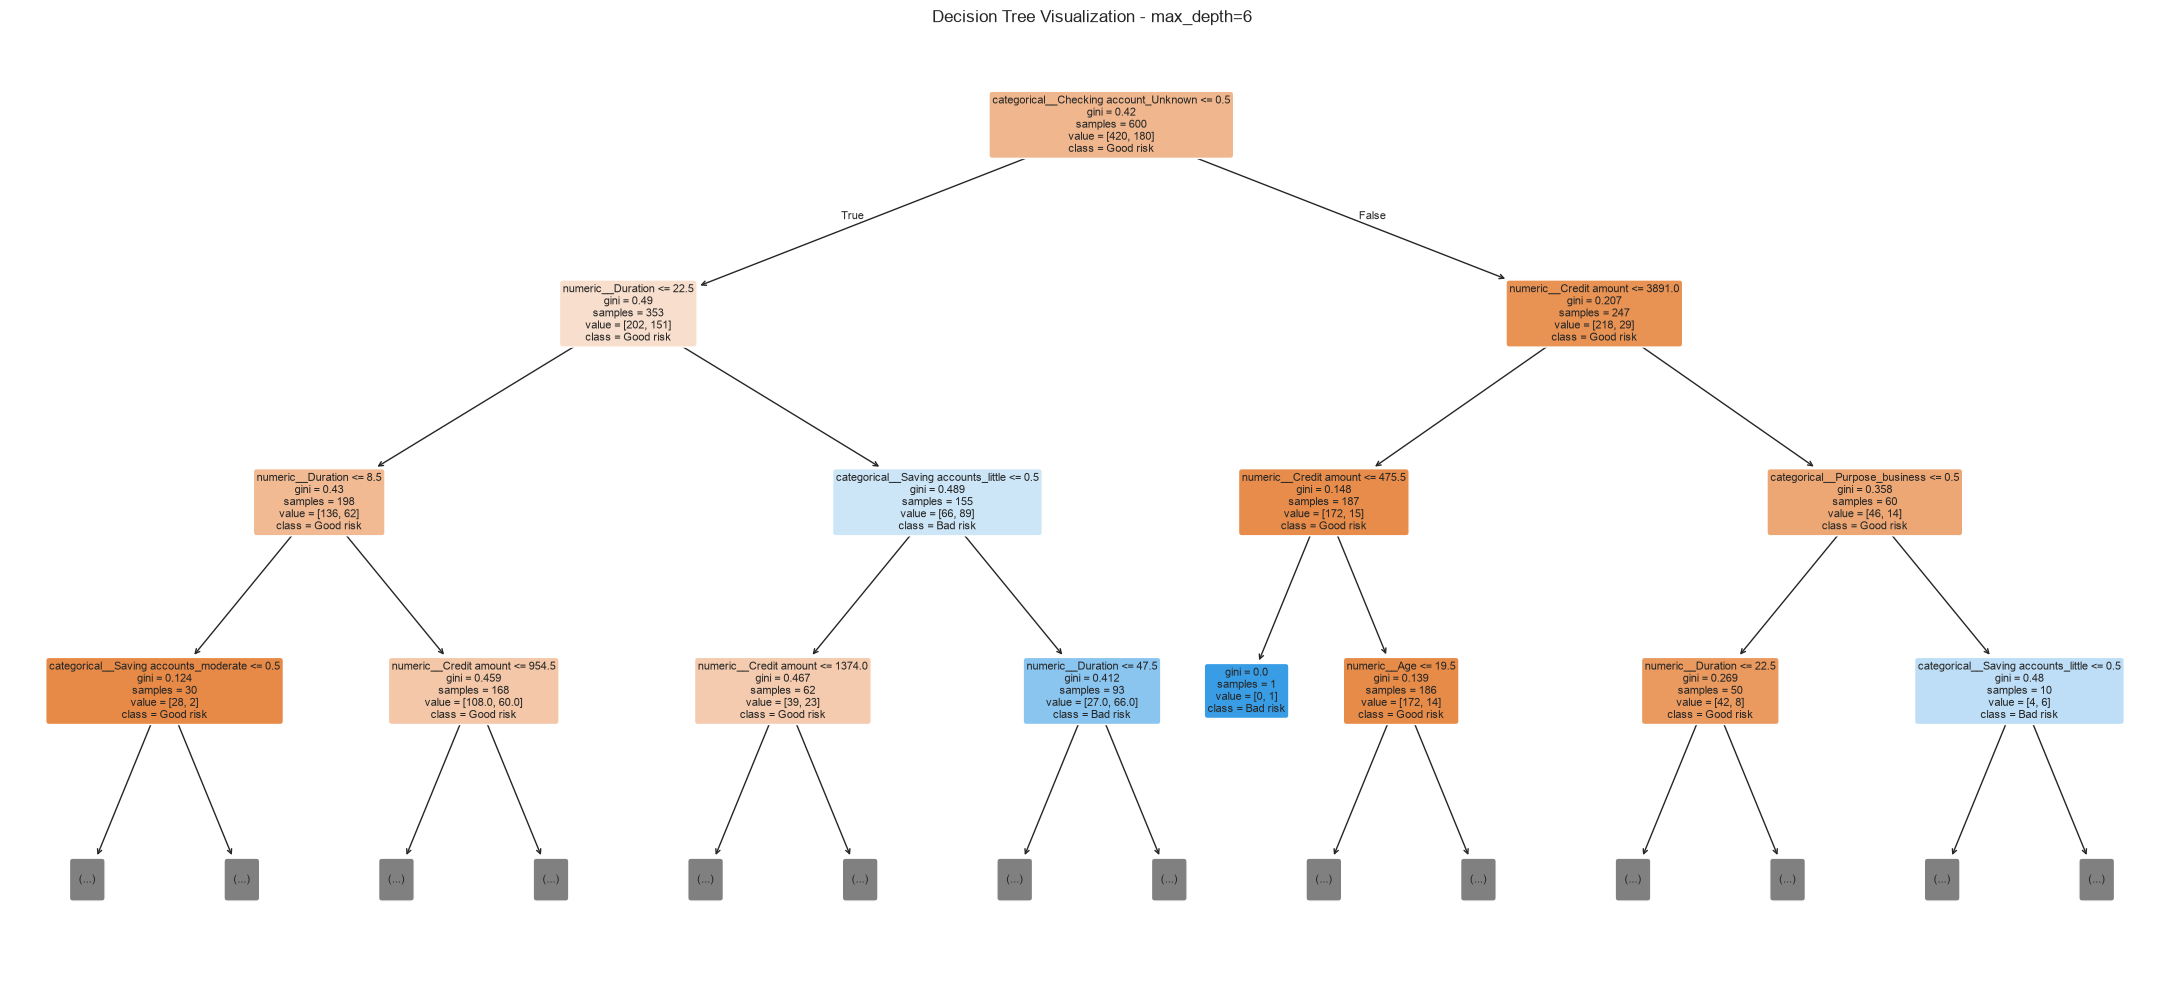

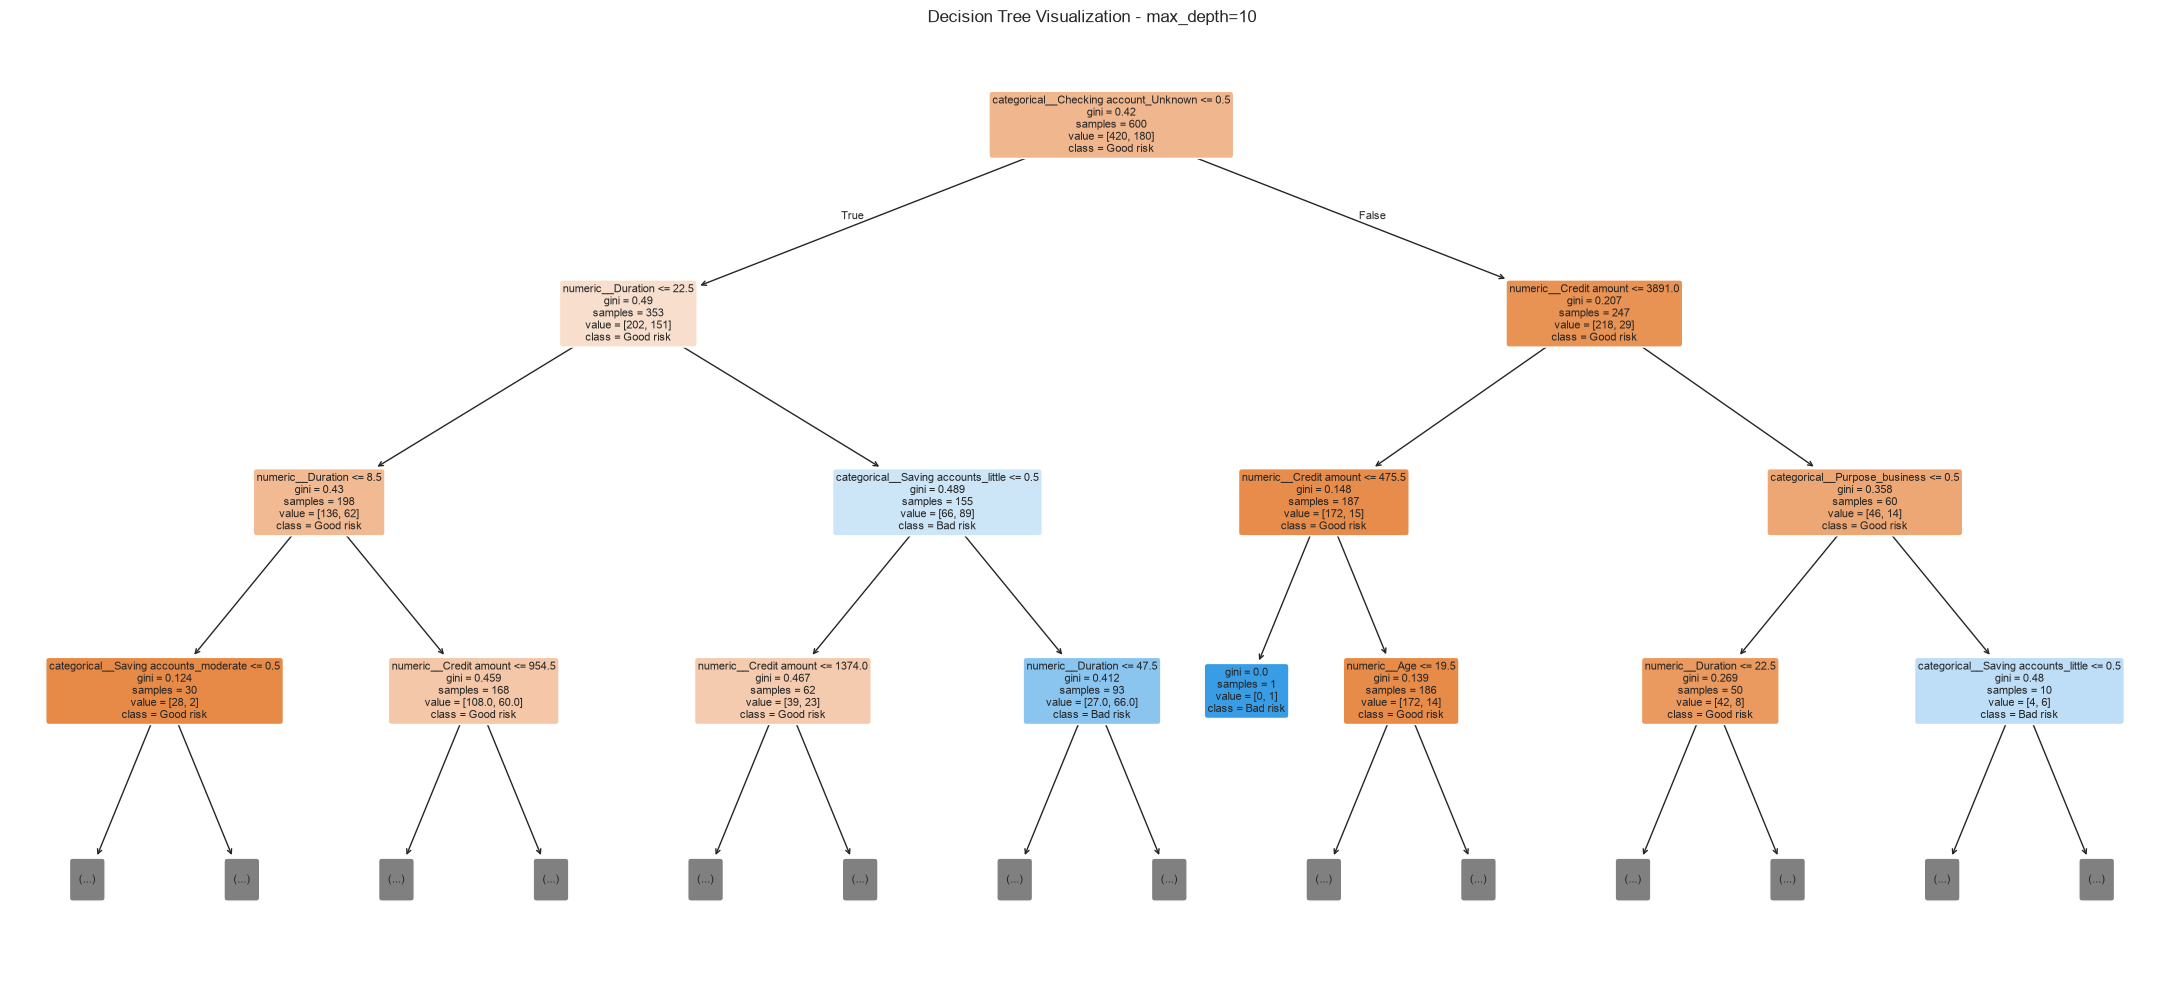

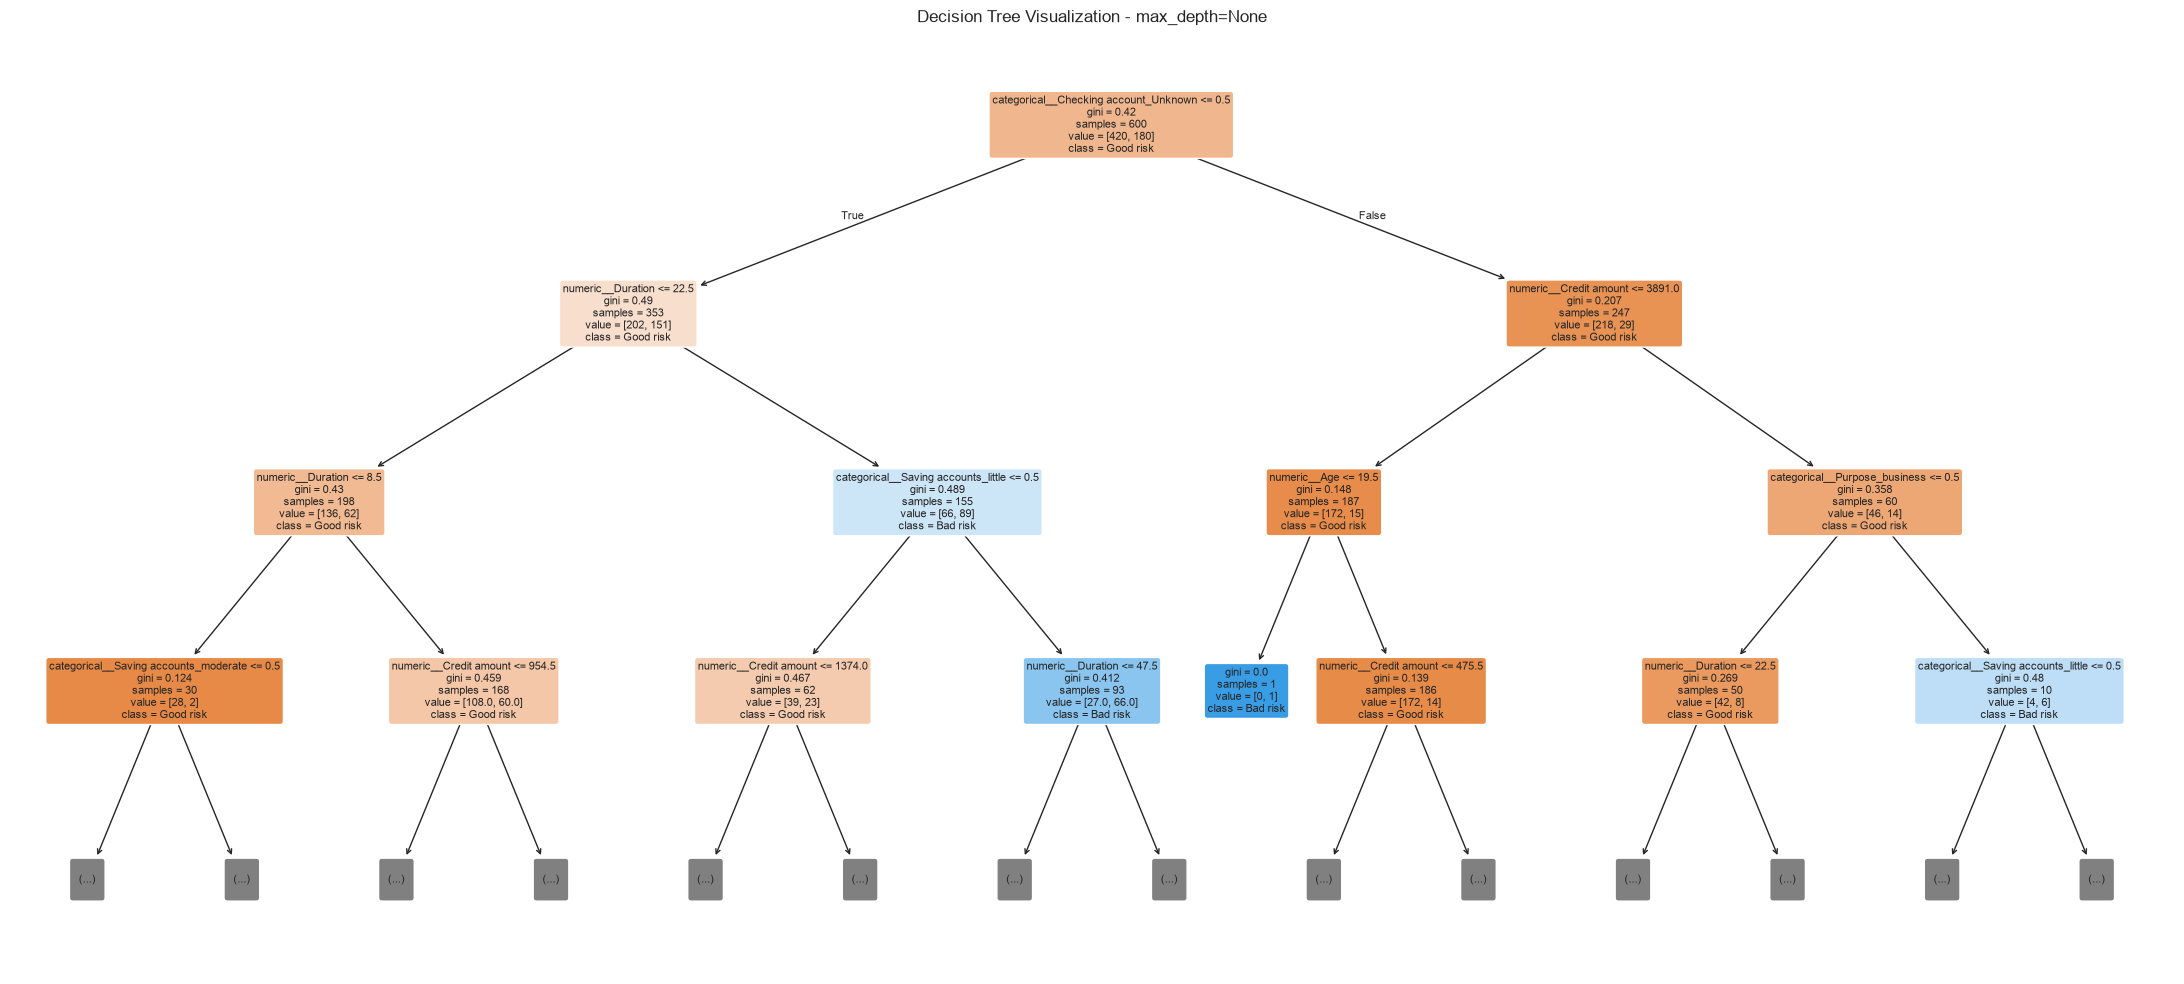

In [41]:
# Part B: Visualize each Decision Tree

for depth, model in depth_models.items():

    plt.figure(figsize=(22, 10))

    plot_tree(
        model,
        feature_names=feature_names,
        class_names=["Good risk", "Bad risk"],
        filled=True,
        rounded=True,
        max_depth=3,
        fontsize=8
    )

    plt.title(
        f"Decision Tree Visualization - max_depth={depth}"
    )

    plt.tight_layout()
    plt.show()

In [42]:
# Part B: Identify the root split for each tree

root_results = []

for depth, model in depth_models.items():

    root_feature_index = model.tree_.feature[0]

    if root_feature_index == _tree.TREE_UNDEFINED:
        root_feature = "Leaf node - no split"
        root_threshold = np.nan

    else:                            
        root_feature = feature_names[root_feature_index]
        root_threshold = model.tree_.threshold[0]

    root_results.append({
        "Max Depth": str(depth),
        "Root Feature": root_feature,
        "Root Threshold": root_threshold
    })                          

root_results_df = pd.DataFrame(root_results)

print("Root split of each Decision Tree:")

display(root_results_df.round(4))

Root split of each Decision Tree:


,Max Depth,Root Feature,Root Threshold
0,2,categorical__Checking account_Unknown,0.5
1,4,categorical__Checking account_Unknown,0.5
2,6,categorical__Checking account_Unknown,0.5
3,10,categorical__Checking account_Unknown,0.5
4,None,categorical__Checking account_Unknown,0.5


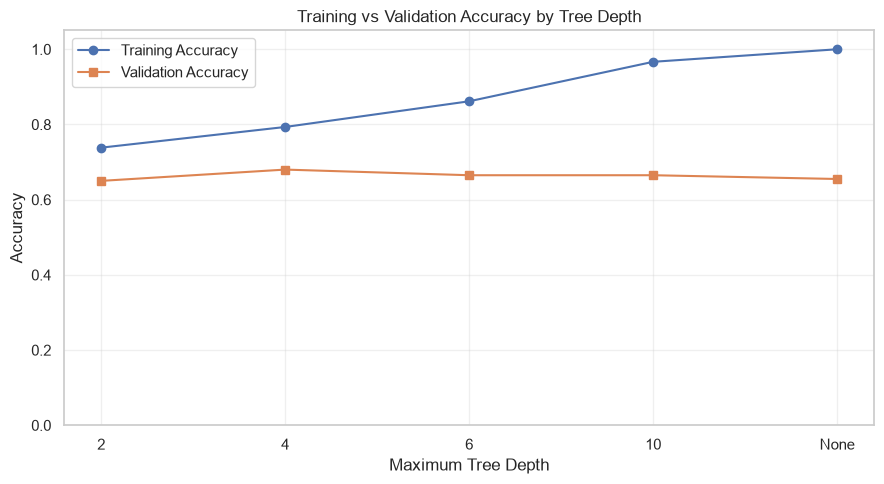

Accuracy comparison:


,Max Depth,Training Accuracy,Validation Accuracy
0,2,0.7383,0.650
1,4,0.7933,0.680
2,6,0.8617,0.665
3,10,0.9667,0.665
4,None,1.0000,0.655


In [43]:
# Compare training and validation accuracy

plt.figure(figsize=(9, 5))

plt.plot(
    depth_results_df["Max Depth"],
    depth_results_df["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_results_df["Max Depth"],
    depth_results_df["Validation Accuracy"],
    marker="s",
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy by Tree Depth")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Accuracy comparison:")

display(
    depth_results_df[
        [
            "Max Depth",
            "Training Accuracy",
            "Validation Accuracy"
        ]
    ].round(4)
)

In [44]:
# Analyze training-validation accuracy gaps

overfitting_results = depth_results_df.copy()

overfitting_results["Accuracy Gap"] = (
    overfitting_results["Training Accuracy"]
    - overfitting_results["Validation Accuracy"]
)

display(
    overfitting_results[
        [
            "Max Depth",
            "Training Accuracy",
            "Validation Accuracy",
            "Accuracy Gap",
            "Actual Tree Depth",
            "Number of Leaves"
        ]
    ].round(4)
)

# Find the depth with the highest validation accuracy
best_val_index = depth_results_df[
    "Validation Accuracy"
].idxmax()

best_val_depth = depth_results_df.loc[
    best_val_index, "Max Depth"
]

print("Depth with highest validation accuracy:", best_val_depth)

# Find the depth with the largest training-validation gap
largest_gap_index = overfitting_results[
    "Accuracy Gap"
].idxmax()

largest_gap_depth = overfitting_results.loc[
    largest_gap_index, "Max Depth"
]

print(
    "Depth with the largest training-validation gap:",
    largest_gap_depth
)

,Max Depth,Training Accuracy,Validation Accuracy,Accuracy Gap,Actual Tree Depth,Number of Leaves
0,2,0.7383,0.650,0.0883,2,4
1,4,0.7933,0.680,0.1133,4,15
2,6,0.8617,0.665,0.1967,6,41
3,10,0.9667,0.665,0.3017,10,108
4,None,1.0000,0.655,0.3450,14,136


Depth with highest validation accuracy: 4
Depth with the largest training-validation gap: None


In [45]:

unpruned_model = depth_models[None]

unpruned_train_predictions = unpruned_model.predict(
    X_train_encoded
)

unpruned_val_predictions = unpruned_model.predict(
    X_val_encoded
)

unpruned_train_accuracy = accuracy_score(
    y_train,
    unpruned_train_predictions
)

unpruned_val_accuracy = accuracy_score(
    y_val,
    unpruned_val_predictions
)

print("Unpruned Tree Analysis")
print("----------------------")
print("Actual tree depth:", unpruned_model.get_depth())
print("Number of leaves:", unpruned_model.get_n_leaves())
print("Training accuracy:", round(unpruned_train_accuracy, 4))
print("Validation accuracy:", round(unpruned_val_accuracy, 4))

if (
    unpruned_train_accuracy > unpruned_val_accuracy
    and unpruned_train_accuracy - unpruned_val_accuracy >= 0.05
):
    print(
        "\nInterpretation: The training accuracy is at least "
        "5 percentage points higher than validation accuracy. "
        "This is evidence of a possible overfitting problem."
    )
else:
    print(
        "\nInterpretation: The accuracy gap is below "
        "5 percentage points, or training accuracy is not higher. "
        "Check the full depth comparison before concluding "
        "whether overfitting occurs."
    )

Unpruned Tree Analysis
----------------------
Actual tree depth: 14
Number of leaves: 136
Training accuracy: 1.0
Validation accuracy: 0.655

Interpretation: The training accuracy is at least 5 percentage points higher than validation accuracy. This is evidence of a possible overfitting problem.


In [46]:
# Numerical feature preprocessing
numeric_pipeline_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical feature preprocessing
categorical_pipeline_cv = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing
preprocessor_cv = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline_cv, numeric_features),
        ("categorical", categorical_pipeline_cv, categorical_features)
    ],
    remainder="drop"
)

# Complete pipeline: preprocessing + Decision Tree
tree_pipeline = Pipeline([
    ("preprocessor", preprocessor_cv),
    ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

print("Preprocessing and Decision Tree pipeline created successfully.")

Preprocessing and Decision Tree pipeline created successfully.


In [47]:
# Define hyperparameter combinations
param_grid = {
    "classifier__max_depth": [3, 5, 7, 10],
    "classifier__min_samples_split": [2, 5, 10, 20]
}

# Five-fold stratified cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Configure GridSearchCV
grid_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

# Train and compare all parameter combinations
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Mean CV Accuracy:", round(grid_search.best_score_, 4))

Best Parameters: {'classifier__max_depth': 5, 'classifier__min_samples_split': 20}
Best Mean CV Accuracy: 0.7367


Best Model Validation Accuracy: 0.665

Validation Classification Report:
              precision    recall  f1-score   support

   Good risk       0.74      0.81      0.77       140
    Bad risk       0.42      0.32      0.36        60

    accuracy                           0.67       200
   macro avg       0.58      0.57      0.57       200
weighted avg       0.64      0.67      0.65       200



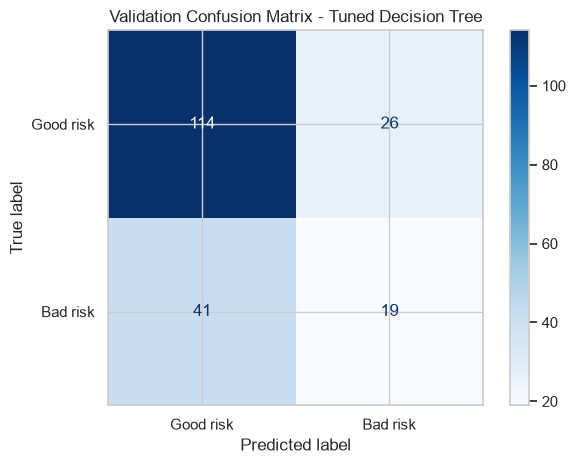

In [48]:
# Retrieve the best model
best_model = grid_search.best_estimator_

# Predict validation labels
val_predictions_best = best_model.predict(X_val)

# Calculate validation accuracy
val_accuracy_best = accuracy_score(y_val, val_predictions_best)

print("Best Model Validation Accuracy:", round(val_accuracy_best, 4))

# Classification report
print("\nValidation Classification Report:")
print(
    classification_report(
        y_val,
        val_predictions_best,
        labels=[0, 1],
        target_names=["Good risk", "Bad risk"],
        zero_division=0
    )
)

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions_best,
    labels=[0, 1],
    display_labels=["Good risk", "Bad risk"],
    cmap="Blues"
)

plt.title("Validation Confusion Matrix - Tuned Decision Tree")
plt.tight_layout()
plt.show()

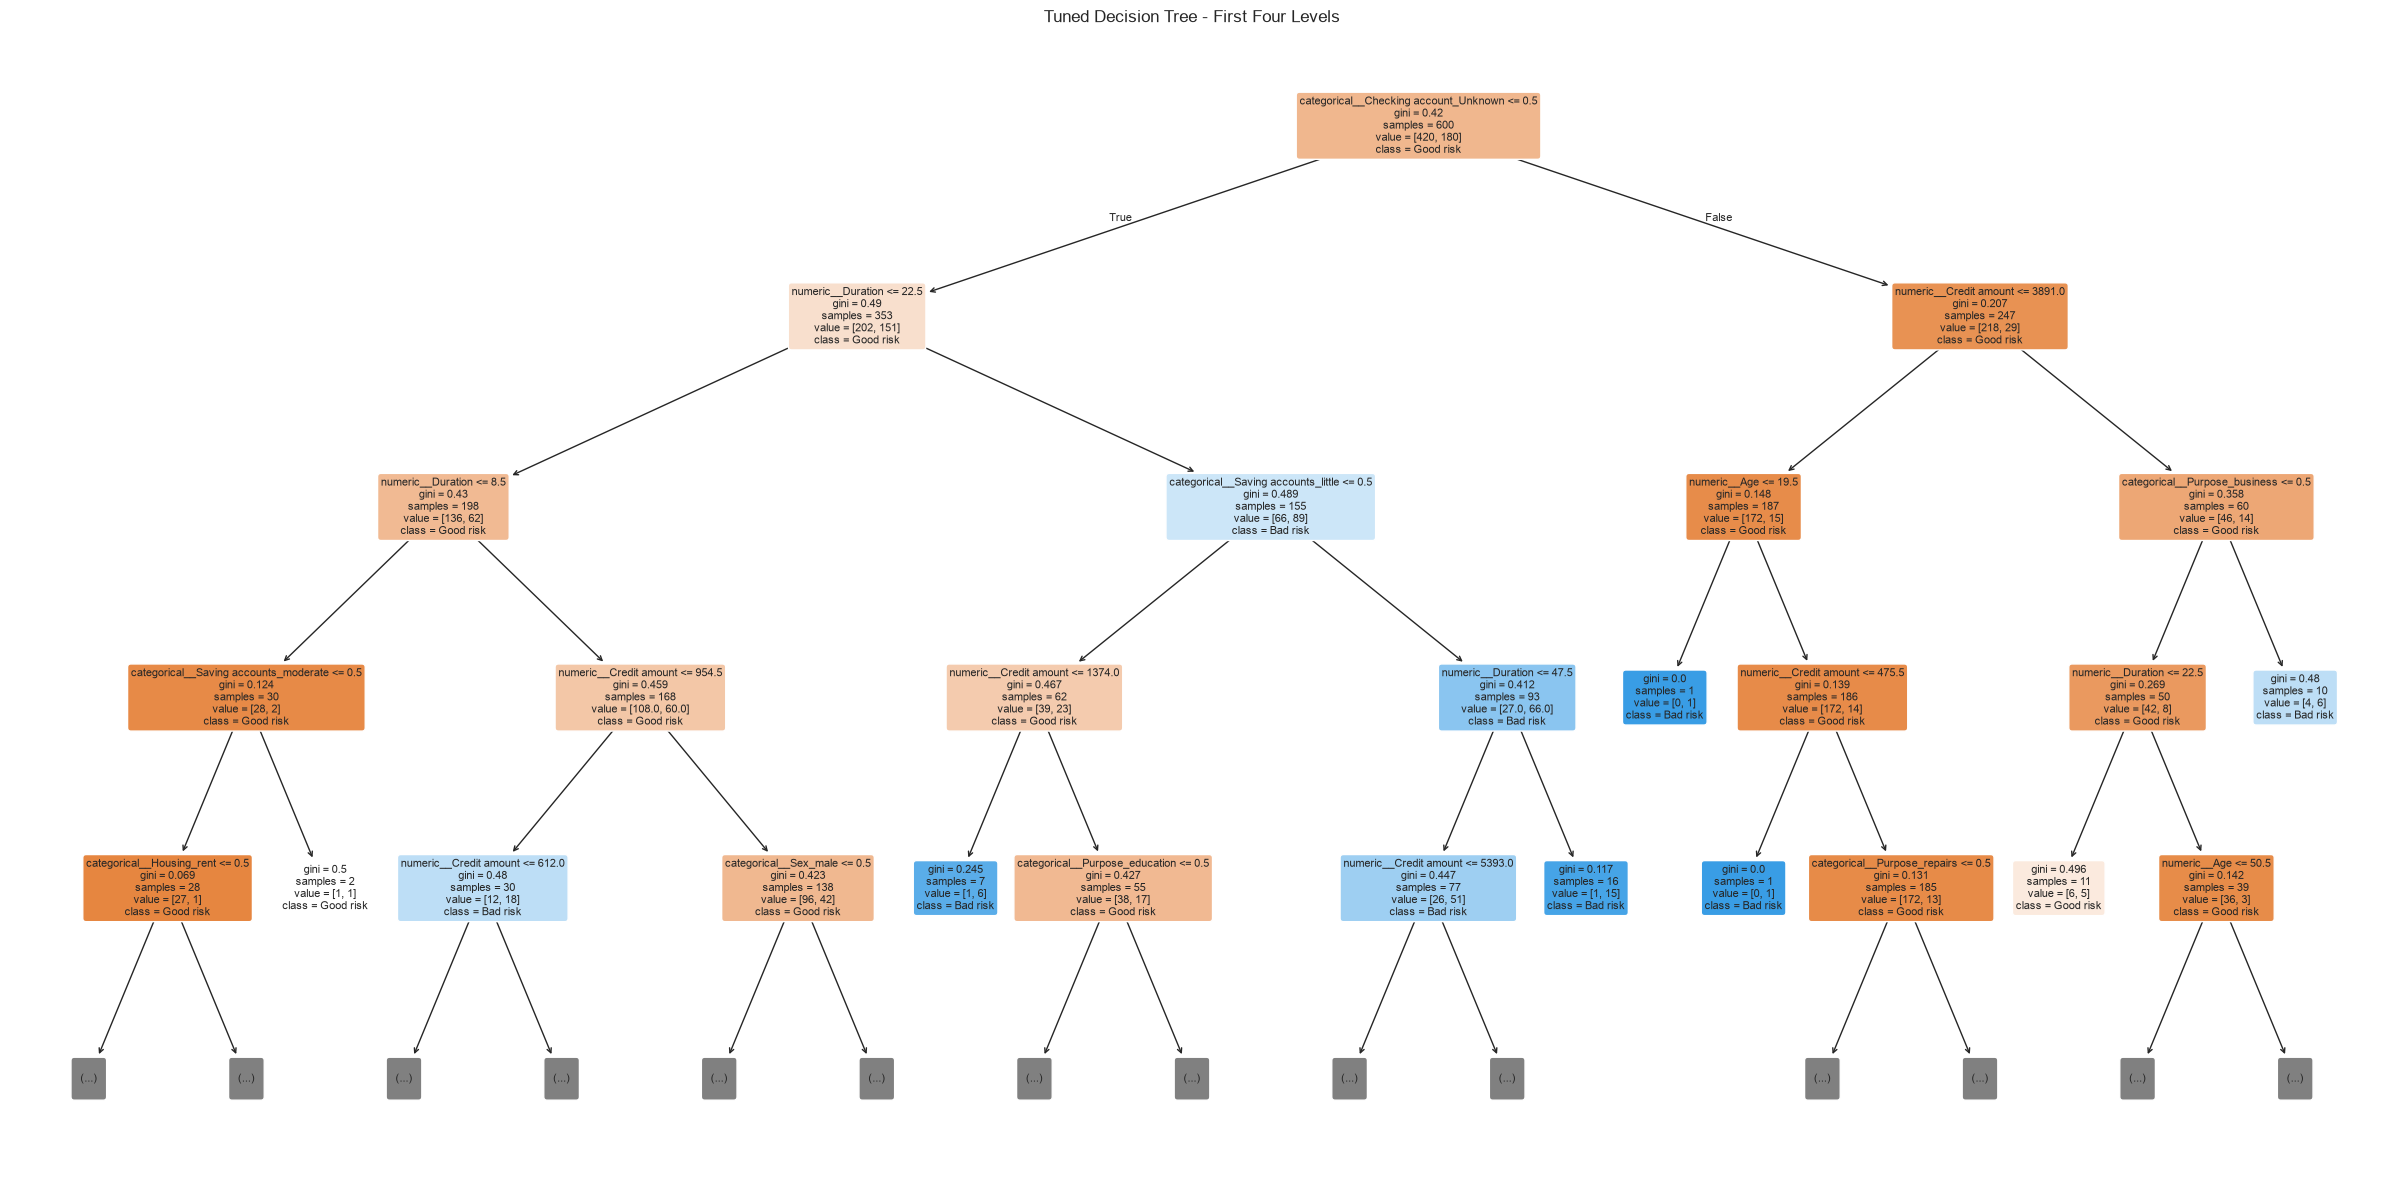

Actual Tree Depth: 5
Number of Leaves: 21


In [49]:
# Extract the fitted preprocessing and tree components
best_preprocessor = best_model.named_steps["preprocessor"]
best_tree = best_model.named_steps["classifier"]

# Get the encoded feature names
best_feature_names = best_preprocessor.get_feature_names_out()

# Visualize the tree
plt.figure(figsize=(24, 12))

plot_tree(
    best_tree,
    feature_names=best_feature_names,
    class_names=["Good risk", "Bad risk"],
    filled=True,
    rounded=True,
    max_depth=4,
    fontsize=8
)

plt.title("Tuned Decision Tree - First Four Levels")
plt.tight_layout()
plt.show()

print("Actual Tree Depth:", best_tree.get_depth())
print("Number of Leaves:", best_tree.get_n_leaves())

In [50]:
def extract_leaf_rules(model, feature_names):
    tree = model.tree_
    rules = []

    def walk(node, conditions):
        feature_index = tree.feature[node]

        # Check whether this node is a leaf
        if feature_index == _tree.TREE_UNDEFINED:
            class_values = tree.value[node][0]
            predicted_class = int(np.argmax(class_values))
            total_samples = int(tree.n_node_samples[node])
            class_total = float(np.sum(class_values))

            bad_risk_share = (
                float(class_values[1] / class_total)
                if class_total > 0 and len(class_values) > 1
                else 0.0
            )

            rules.append({
                "Rule": " AND ".join(conditions) if conditions else "All customers",
                "Predicted Class": (
                    "Bad risk" if predicted_class == 1 else "Good risk"
                ),
                "Training Samples": total_samples,
                "Bad Risk Share": bad_risk_share
            })
            return

        feature_name = feature_names[feature_index]
        threshold = tree.threshold[node]

        # Left branch: feature <= threshold
        walk(
            tree.children_left[node],
            conditions + [f"{feature_name} <= {threshold:.3f}"]
        )

        # Right branch: feature > threshold
        walk(
            tree.children_right[node],
            conditions + [f"{feature_name} > {threshold:.3f}"]
        )

    walk(0, [])
    return pd.DataFrame(rules)


# Extract all leaf rules
leaf_rules_df = extract_leaf_rules(best_tree, best_feature_names)

# Display five rules covering the most training samples
top_five_rules = (
    leaf_rules_df
    .sort_values("Training Samples", ascending=False)
    .head(5)
    .copy()
)

top_five_rules["Bad Risk Share"] *= 100

display(
    top_five_rules.rename(
        columns={"Bad Risk Share": "Bad Risk Share (%)"}
    ).round(2)
)

,Rule,Predicted Class,Training Samples,Bad Risk Share (%)
15,categorical__Checking account_Unknown > 0.500 ...,Good risk,181,6.08
6,categorical__Checking account_Unknown <= 0.500...,Good risk,92,22.83
8,categorical__Checking account_Unknown <= 0.500...,Good risk,53,28.30
10,categorical__Checking account_Unknown <= 0.500...,Bad risk,50,78.00
5,categorical__Checking account_Unknown <= 0.500...,Good risk,46,45.65


In [51]:
high_risk_segments = leaf_rules_df[
    leaf_rules_df["Training Samples"] >= 10
].copy()

high_risk_segments = high_risk_segments.sort_values(
    by=["Bad Risk Share", "Training Samples"],
    ascending=[False, False]
).head(5)

high_risk_segments["Bad Risk Share"] *= 100

display(
    high_risk_segments.rename(
        columns={"Bad Risk Share": "Bad Risk Share (%)"}
    ).round(2)
)

,Rule,Predicted Class,Training Samples,Bad Risk Share (%)
12,categorical__Checking account_Unknown <= 0.500...,Bad risk,16,93.75
4,categorical__Checking account_Unknown <= 0.500...,Bad risk,23,78.26
10,categorical__Checking account_Unknown <= 0.500...,Bad risk,50,78.00
20,categorical__Checking account_Unknown > 0.500 ...,Bad risk,10,60.00
5,categorical__Checking account_Unknown <= 0.500...,Good risk,46,45.65


In [52]:
print("High-Risk Customer Segments\n")

for index, row in high_risk_segments.reset_index(drop=True).iterrows():
    print(f"Segment {index + 1}")
    print("Conditions:", row["Rule"])
    print("Predicted Class:", row["Predicted Class"])
    print("Training Customers:", row["Training Samples"])
    print("Bad Risk Share:", f'{row["Bad Risk Share"]:.2f}%')
    print("-" * 60)

High-Risk Customer Segments

Segment 1
Conditions: categorical__Checking account_Unknown <= 0.500 AND numeric__Duration > 22.500 AND categorical__Saving accounts_little > 0.500 AND numeric__Duration > 47.500
Predicted Class: Bad risk
Training Customers: 16
Bad Risk Share: 93.75%
------------------------------------------------------------
Segment 2
Conditions: categorical__Checking account_Unknown <= 0.500 AND numeric__Duration <= 22.500 AND numeric__Duration > 8.500 AND numeric__Credit amount <= 954.500 AND numeric__Credit amount > 612.000
Predicted Class: Bad risk
Training Customers: 23
Bad Risk Share: 78.26%
------------------------------------------------------------
Segment 3
Conditions: categorical__Checking account_Unknown <= 0.500 AND numeric__Duration > 22.500 AND categorical__Saving accounts_little > 0.500 AND numeric__Duration <= 47.500 AND numeric__Credit amount <= 5393.000
Predicted Class: Bad risk
Training Customers: 50
Bad Risk Share: 78.00%
-----------------------------

Final Test Accuracy: 0.69

Test Classification Report:
              precision    recall  f1-score   support

   Good risk       0.76      0.82      0.79       140
    Bad risk       0.48      0.38      0.43        60

    accuracy                           0.69       200
   macro avg       0.62      0.60      0.61       200
weighted avg       0.67      0.69      0.68       200



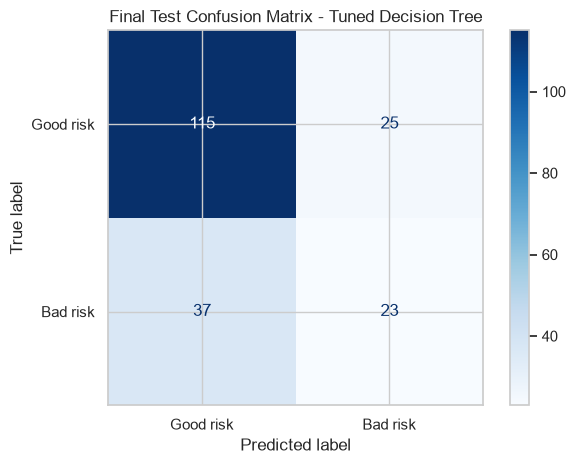

In [53]:
# Predict on untouched test data
test_predictions_best = best_model.predict(X_test)

# Test accuracy
test_accuracy_best = accuracy_score(y_test, test_predictions_best)

print("Final Test Accuracy:", round(test_accuracy_best, 4))

# Test classification report
print("\nTest Classification Report:")
print(
    classification_report(
        y_test,
        test_predictions_best,
        labels=[0, 1],
        target_names=["Good risk", "Bad risk"],
        zero_division=0
    )
)

# Test confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions_best,
    labels=[0, 1],
    display_labels=["Good risk", "Bad risk"],
    cmap="Blues"
)

plt.title("Final Test Confusion Matrix - Tuned Decision Tree")
plt.tight_layout()
plt.show()